# 03_02 The Dirichlet and Dirichlet-Multinomial Distributions

**Learning objectives**
- Understand the **Dirichlet** as a distribution over **probability vectors** (points on the simplex), the multi-category version of the Beta.
- Read its parameters $\boldsymbol\alpha$ (concentration and shape), derive its mean, variance, covariance and marginals.
- Use **conjugacy** with the Multinomial (posterior = Dirichlet($\boldsymbol\alpha+$ counts)) and the **Dirichlet-Multinomial** predictive.
- Solve a market-share problem by hand, in code and by simulation, and see topic mixtures (the idea behind LDA).

**Prerequisites:** [01_05 Multinomial](../../module_01_discrete/notebooks/01_05_uniform_categorical_multinomial.ipynb), [02_04 Beta](../../module_02_continuous/notebooks/02_04_beta.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **probability vector** $\mathbf p=(p_1,\dots,p_K)$ has $p_i\ge0$ and $\sum p_i=1$; all such vectors form the **simplex** (a triangle for $K=3$).
- **Multinomial($n,\mathbf p$):** counts of $K$ categories in $n$ draws; $\mathrm{Cov}(X_i,X_j)=-np_ip_j$.
- **Beta($a,b$)** is the distribution of one probability; Beta prior + Binomial data = Beta posterior.
- **Gamma($a$)** variables $G_i$: the normalized vector $G_i/\sum G_j$ is Dirichlet (derived below).

## 3. Intuition and story

A single probability $p$ can be given a Beta distribution. But often we are unsure about a **whole set of probabilities that add to 1**: the market shares of 3 brands, the mix of topics in a document, the proportions of word types. The **Dirichlet** distribution is a distribution over such vectors: each draw is itself a probability vector.

Think of **$\alpha_i-1$ as "already observed counts"** of category $i$ (with $\alpha_i=1$ meaning no prior information). The total $\alpha_0=\sum\alpha_i$ is the **concentration**: the larger it is, the more tightly the draws cluster around the mean $\boldsymbol\alpha/\alpha_0$. Small $\alpha_i<1$ pushes draws toward the corners of the simplex (sparse mixtures, dominated by one category).

## 4. Formal definition

$\mathbf p\sim\text{Dirichlet}(\boldsymbol\alpha)$, $\alpha_i>0$, on the simplex $\{p_i\ge0,\sum p_i=1\}$:
$$f(\mathbf p)=\frac{\Gamma(\alpha_0)}{\prod_i\Gamma(\alpha_i)}\prod_{i=1}^Kp_i^{\alpha_i-1},\qquad\alpha_0=\sum_i\alpha_i.$$
For $K=2$ this is the Beta. **Dirichlet-Multinomial:** if $\mathbf p\sim\text{Dir}(\boldsymbol\alpha)$ and $\mathbf X\mid\mathbf p\sim\text{Mult}(n,\mathbf p)$, the marginal law of $\mathbf X$ is Dirichlet-Multinomial (a Multinomial with extra variation).

**`scipy`:** `stats.dirichlet(alpha)` (`pdf`, `rvs`, `mean`, `var`); `stats.dirichlet_multinomial(alpha, n)` in recent versions; `rng.dirichlet(alpha)`.

## 5. Derivations

**Mean, variance, covariance.** With $\alpha_0=\sum\alpha_i$:
$$E[p_i]=\frac{\alpha_i}{\alpha_0},\qquad\mathrm{Var}(p_i)=\frac{\alpha_i(\alpha_0-\alpha_i)}{\alpha_0^2(\alpha_0+1)},\qquad\mathrm{Cov}(p_i,p_j)=-\frac{\alpha_i\alpha_j}{\alpha_0^2(\alpha_0+1)}\ (i\ne j).$$
The covariance is negative because the shares must add up to 1 (as for Multinomial counts). Larger $\alpha_0$ shrinks the variance.

**Marginals are Beta.** $p_i\sim\text{Beta}(\alpha_i,\ \alpha_0-\alpha_i)$ (merge the other categories into "not $i$").

**Construction from Gammas.** If $G_i\sim\text{Gamma}(\alpha_i,1)$ are independent, then $\big(G_1/S,\dots,G_K/S\big)$ with $S=\sum G_j$ is Dirichlet($\boldsymbol\alpha$) (and independent of $S\sim\text{Gamma}(\alpha_0)$). This is how samples are generated, and shows the Beta($\alpha,\beta$)$=G_1/(G_1+G_2)$ link.

**Conjugacy.** Prior $\pi(\mathbf p)\propto\prod p_i^{\alpha_i-1}$; data counts $\mathbf x$ with $\sum x_i=n$: likelihood $\propto\prod p_i^{x_i}$. Multiply:
$$\pi(\mathbf p\mid\mathbf x)\propto\prod p_i^{\alpha_i+x_i-1}\quad\Longrightarrow\quad\mathbf p\mid\mathbf x\sim\text{Dirichlet}(\boldsymbol\alpha+\mathbf x).$$
Updating is just **adding the counts to the parameters**; the posterior mean is $\frac{\alpha_i+x_i}{\alpha_0+n}$, a weighted average of the prior mean and the observed proportions.

**Predictive probability.** The probability that the next draw is category $i$ given the data equals the posterior mean $\frac{\alpha_i+x_i}{\alpha_0+n}$ (the "rule of succession", Laplace smoothing when $\alpha_i=1$).

**Dirichlet-Multinomial moments.** $E[X_i]=n\frac{\alpha_i}{\alpha_0}$ and $\mathrm{Var}(X_i)=n\,p_i(1-p_i)\,\frac{n+\alpha_0}{1+\alpha_0}$ with $p_i=\alpha_i/\alpha_0$: the Multinomial variance times an **overdispersion factor** $\frac{n+\alpha_0}{1+\alpha_0}>1$.

**In plain words.** A Dirichlet is a bag of "pseudo-counts" for each category; observing real counts simply adds to the bag.

## 6. Properties and relationships

- **Beta is the $K=2$ Dirichlet;** the Dirichlet is the conjugate prior of the Categorical and Multinomial.
- **Shapes (K = 3):** all $\alpha_i=1$: uniform on the triangle; all $\alpha_i>1$: a bump at the center; all $\alpha_i<1$: mass at the corners and edges (sparse).
- **Aggregation:** merging categories gives a Dirichlet with the merged $\alpha$'s added.
- **Overdispersion:** Dirichlet-Multinomial counts vary more than Multinomial counts (compare Negative Binomial vs Poisson).
- **LDA (topic models):** each document has topic proportions $\boldsymbol\theta\sim\text{Dir}(\boldsymbol\alpha)$; a small $\alpha$ means documents focus on few topics.

## 7. 2D visuals

### 7.1 The Dirichlet on the simplex
A point of the triangle is a probability vector (p1, p2, p3). We map it to the plane with barycentric coordinates and show the density (brighter = more likely) for four settings.

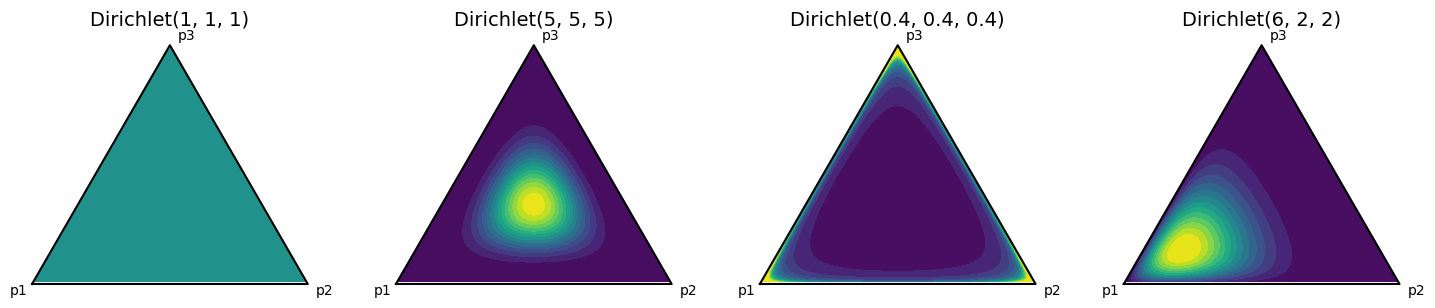

In [2]:
corners = np.array([[0.0, 0.0], [1.0, 0.0], [0.5, np.sqrt(3) / 2]])        # triangle vertices for categories 1, 2, 3

def to_triangle(p):
    """Map probability vectors (rows summing to 1) to 2D points of the equilateral triangle."""
    return p @ corners

grid = np.array([[a, b, 1 - a - b] for a in np.linspace(0.005, 0.995, 120) for b in np.linspace(0.005, 0.995, 120) if a + b < 0.995])
points = to_triangle(grid)
settings = [(1, 1, 1), (5, 5, 5), (0.4, 0.4, 0.4), (6, 2, 2)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, alpha in zip(axes, settings):
    density = stats.dirichlet(alpha).pdf(grid.T)
    contour = ax.tricontourf(points[:, 0], points[:, 1], np.minimum(density, np.percentile(density, 99)), levels=14, cmap="viridis")
    ax.plot(*np.vstack([corners, corners[0]]).T, color="black")
    for label, corner in zip(["p1", "p2", "p3"], corners):
        ax.text(corner[0] + (0.03 if corner[0] > 0.2 else -0.08), corner[1] - 0.04 if corner[1] < 0.5 else corner[1] + 0.02, label)
    ax.set_title(f"Dirichlet{alpha}")
    ax.set_aspect("equal")
    ax.axis("off")
plt.show()

### 7.2 Draws from the Dirichlet: sparse versus smooth mixtures
Each row is one draw (a probability vector), shown as a stacked bar. Small alpha gives draws dominated by one category; large alpha gives similar mixtures.

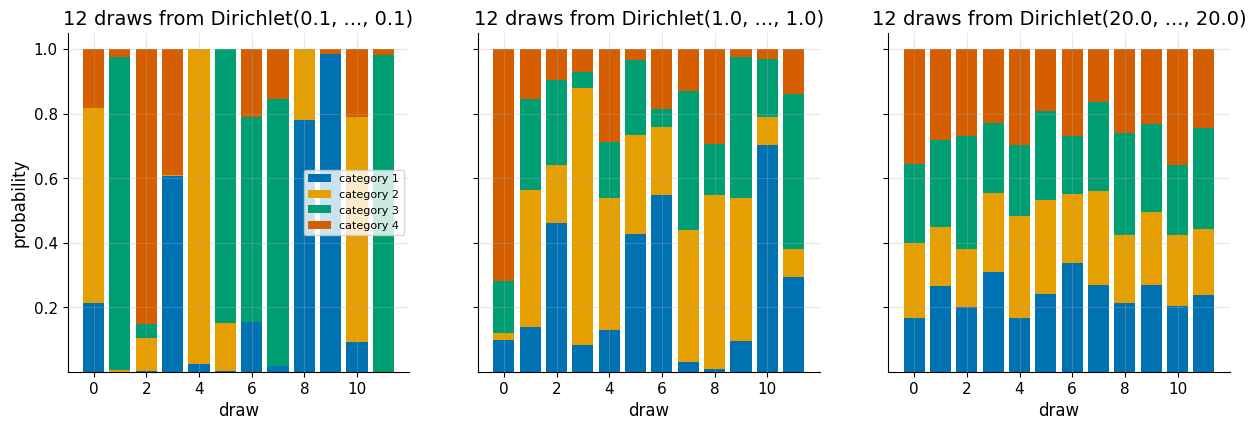

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, alpha_value in zip(axes, [0.1, 1.0, 20.0]):
    draws = rng.dirichlet([alpha_value] * 4, size=12)
    bottom = np.zeros(12)
    for k, color in enumerate(COLORS[:4]):
        ax.bar(range(12), draws[:, k], bottom=bottom, color=color, label=f"category {k + 1}")
        bottom += draws[:, k]
    ax.set_title(f"12 draws from Dirichlet({alpha_value}, ..., {alpha_value})")
    ax.set_xlabel("draw")
axes[0].set_ylabel("probability")
axes[0].legend(fontsize=8)
plt.show()

### 7.3 Marginals are Beta distributions
For Dirichlet(4, 3, 2), the first component is Beta(4, 5): a histogram of simulated values matches it.

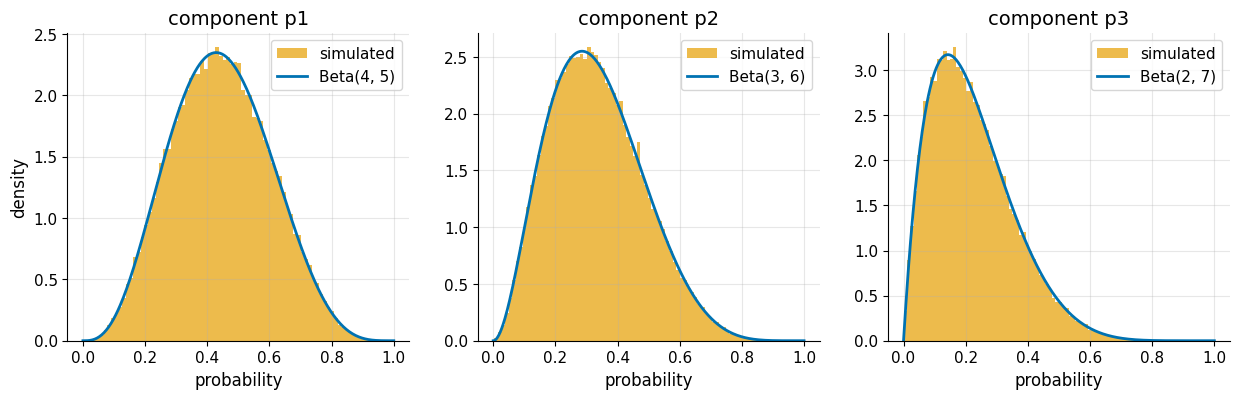

means: [0.4452 0.3333 0.2215] theory [0.4444 0.3333 0.2222]
covariance(p1, p2): -0.01487  theory -0.01481


In [4]:
alpha = np.array([4.0, 3.0, 2.0])
draws = rng.dirichlet(alpha, size=100_000)
grid_p = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, ax in enumerate(axes):
    ax.hist(draws[:, k], bins=80, density=True, color=SIM, alpha=0.7, label="simulated")
    ax.plot(grid_p, stats.beta(alpha[k], alpha.sum() - alpha[k]).pdf(grid_p), color=MAIN, linewidth=2, label=f"Beta({alpha[k]:.0f}, {alpha.sum() - alpha[k]:.0f})")
    ax.set_title(f"component p{k + 1}")
    ax.set_xlabel("probability")
    ax.legend()
axes[0].set_ylabel("density")
plt.show()
print("means:", draws.mean(axis=0).round(4), "theory", (alpha / alpha.sum()).round(4))
print("covariance(p1, p2):", round(np.cov(draws[:, 0], draws[:, 1])[0, 1], 5), " theory", round(-alpha[0] * alpha[1] / (alpha.sum() ** 2 * (alpha.sum() + 1)), 5))

## 8. 3D visuals

### 8.1 Static: the Dirichlet density as a surface over the simplex
The height is the density at each probability vector (colored triangle base).

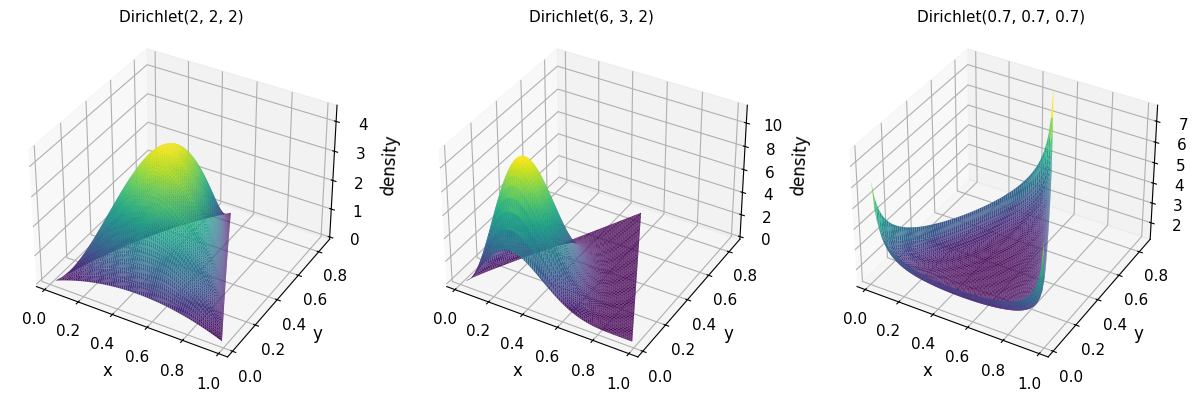

In [5]:
def density_surface(alpha):
    """Return triangle coordinates and Dirichlet(alpha) density values on a grid inside the simplex."""
    pts = np.array([[a, b, 1 - a - b] for a in np.linspace(0.01, 0.98, 90) for b in np.linspace(0.01, 0.98, 90) if a + b < 0.99])
    xy = to_triangle(pts)
    return xy, stats.dirichlet(alpha).pdf(pts.T)

fig = plt.figure(figsize=(15, 5))
for position, alpha in enumerate([(2, 2, 2), (6, 3, 2), (0.7, 0.7, 0.7)], start=1):
    ax = fig.add_subplot(1, 3, position, projection="3d")
    xy, z = density_surface(alpha)
    ax.plot_trisurf(xy[:, 0], xy[:, 1], np.minimum(z, 12), cmap="viridis", linewidth=0)
    ax.set_title(f"Dirichlet{alpha}", fontsize=11)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("density")
    ax.view_init(elev=35, azim=-60)
plt.show()

### 8.2 Static: 3D scatter of samples inside the simplex triangle in (p1, p2, p3) space
All points lie on the plane p1 + p2 + p3 = 1.

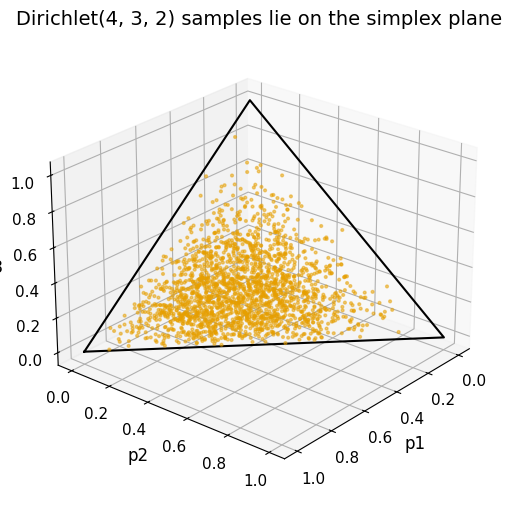

In [6]:
fig = plt.figure(figsize=(7.5, 6))
ax = fig.add_subplot(projection="3d")
samples3 = rng.dirichlet([4, 3, 2], size=2000)
ax.scatter(samples3[:, 0], samples3[:, 1], samples3[:, 2], s=4, alpha=0.5, color=SIM)
ax.plot([1, 0, 0, 1], [0, 1, 0, 0], [0, 0, 1, 0], color="black")
ax.set_title("Dirichlet(4, 3, 2) samples lie on the simplex plane")
ax.set_xlabel("p1"); ax.set_ylabel("p2"); ax.set_zlabel("p3")
ax.view_init(elev=25, azim=40)
plt.show()

### 8.3 Interactive Plotly version of the samples

In [7]:
fig = go.Figure(go.Scatter3d(x=samples3[:, 0], y=samples3[:, 1], z=samples3[:, 2], mode="markers", marker=dict(size=2, color=samples3[:, 0], colorscale="Viridis", showscale=True)))
fig.add_trace(go.Scatter3d(x=[1, 0, 0, 1], y=[0, 1, 0, 0], z=[0, 0, 1, 0], mode="lines", line=dict(color="black"), showlegend=False))
fig.update_layout(title="Dirichlet(4, 3, 2) samples on the simplex", width=750, height=550, scene=dict(xaxis_title="p1", yaxis_title="p2", zaxis_title="p3"))
fig.show()

## 9. Simulation vs theory

### 9.1 Building a Dirichlet from Gamma variables
Normalizing independent Gamma(alpha_i) draws gives Dirichlet(alpha); the means and variances match the formulas.

In [8]:
alpha = np.array([4.0, 3.0, 2.0])
gammas = rng.gamma(shape=alpha, size=(200_000, 3))
by_gammas = gammas / gammas.sum(axis=1, keepdims=True)
alpha0 = alpha.sum()
print("mean from Gammas :", by_gammas.mean(axis=0).round(4), " theory", (alpha / alpha0).round(4))
print("var from Gammas  :", by_gammas.var(axis=0).round(5), " theory", (alpha * (alpha0 - alpha) / (alpha0**2 * (alpha0 + 1))).round(5))
print("KS test of p1 vs Beta(4, 5): p-value =", round(stats.kstest(by_gammas[:, 0], stats.beta(4, 5).cdf).pvalue, 3))

mean from Gammas : [0.4444 0.333  0.2226]  theory [0.4444 0.3333 0.2222]
var from Gammas  : [0.02467 0.02224 0.01729]  theory [0.02469 0.02222 0.01728]
KS test of p1 vs Beta(4, 5): p-value = 0.391


### 9.2 Dirichlet-Multinomial: overdispersion
Drawing p from a Dirichlet and then counts from a Multinomial gives counts that vary more than a plain Multinomial with the same mean.

variance of the count of category 1: Multinomial 8.03 | Dirichlet-Multinomial 43.19 | theory 43.64 (overdispersion factor 5.45)


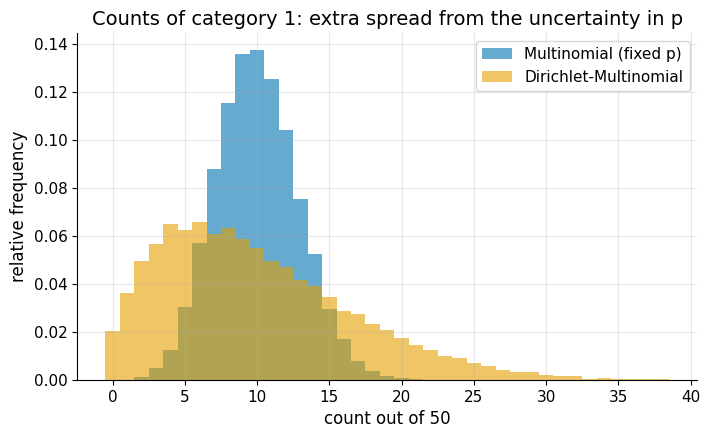

In [9]:
n_trials, alpha_dm = 50, np.array([2.0, 3.0, 5.0])
p_draws = rng.dirichlet(alpha_dm, size=100_000)
counts_dm = np.array([rng.multinomial(n_trials, p) for p in p_draws[:20_000]])
mean_p = alpha_dm / alpha_dm.sum()
counts_plain = rng.multinomial(n_trials, mean_p, size=20_000)
factor = (n_trials + alpha_dm.sum()) / (1 + alpha_dm.sum())
print("variance of the count of category 1: Multinomial", counts_plain[:, 0].var().round(2), "| Dirichlet-Multinomial", counts_dm[:, 0].var().round(2),
      "| theory", round(n_trials * mean_p[0] * (1 - mean_p[0]) * factor, 2), f"(overdispersion factor {factor:.2f})")
fig, ax = plt.subplots()
bins = np.arange(0, 40) - 0.5
ax.hist(counts_plain[:, 0], bins=bins, density=True, alpha=0.6, color=MAIN, label="Multinomial (fixed p)")
ax.hist(counts_dm[:, 0], bins=bins, density=True, alpha=0.6, color=SIM, label="Dirichlet-Multinomial")
ax.set_title("Counts of category 1: extra spread from the uncertainty in p")
ax.set_xlabel("count out of 50")
ax.set_ylabel("relative frequency")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [10]:
dirichlet = stats.dirichlet([53, 32, 18])
print("mean           :", dirichlet.mean().round(4))
print("var            :", dirichlet.var().round(6))
print("pdf at the mean:", round(dirichlet.pdf(dirichlet.mean()), 3))
print("rvs(2)         :", dirichlet.rvs(size=2, random_state=1).round(3).tolist())
print("entropy        :", round(dirichlet.entropy(), 3))
print("marginal Beta  : p1 ~ Beta(53, 50): mean", round(stats.beta(53, 50).mean(), 4))
print("rng.dirichlet  :", rng.dirichlet([1, 1, 1]).round(3))

mean           : [0.5146 0.3107 0.1748]
var            : [0.002402 0.002059 0.001387]
pdf at the mean: 97.295
rvs(2)         : [[0.598, 0.259, 0.142], [0.442, 0.415, 0.143]]
entropy        : -3.608
marginal Beta  : p1 ~ Beta(53, 50): mean 0.5146
rng.dirichlet  : [0.239 0.76  0.001]


## 11. Real-world worked example: uncertainty about market shares

**Scenario (illustrative numbers).** A survey of **100 customers** finds **52 prefer brand A, 31 brand B and 17 brand C**. We want the uncertainty about the true market shares $(p_A,p_B,p_C)$, starting from the flat prior Dirichlet(1,1,1).

**Questions**
1. What is the **posterior** and the posterior **mean and SD** of each share?
2. What is the probability that brand A has a **majority** ($p_A>0.5$)?
3. What is the probability that brand A is the **market leader by more than 10 points over B** ($p_A-p_B>0.10$)?

### 11.1 By hand
**Posterior.** Add the counts: Dirichlet$(1+52,\,1+31,\,1+17)=$ Dirichlet$(53,32,18)$, $\alpha_0=103$.

**Q1.** Means: $\frac{53}{103}=0.5146$, $\frac{32}{103}=0.3107$, $\frac{18}{103}=0.1748$. Variance of $p_A$: $\frac{53\cdot50}{103^2\cdot104}=0.002402$, SD $=0.0490$; for $p_B$: $\frac{32\cdot71}{103^2\cdot104}=0.002059$, SD $=0.0454$; for $p_C$: SD $=0.0374$.

**Q2.** The marginal of $p_A$ is Beta$(53,50)$; $P(p_A>0.5)$ is a Beta tail, computed below by integrating the Beta density in a plain loop (normal approximation: $z=\frac{0.5-0.5146}{0.049}=-0.30$, so $\approx0.62$).

**Q3.** $p_A-p_B$ has no simple closed form; we use simulation by drawing from the posterior (and check that two independent runs agree).

In [11]:
import math

counts = np.array([52, 31, 17])
prior = np.array([1.0, 1.0, 1.0])
posterior_alpha = prior + counts
alpha0 = posterior_alpha.sum()

means_hand = posterior_alpha / alpha0
variances_hand = posterior_alpha * (alpha0 - posterior_alpha) / (alpha0**2 * (alpha0 + 1))
print("posterior Dirichlet", posterior_alpha, " means", means_hand.round(4), " SDs", np.sqrt(variances_hand).round(4))

def beta_pdf_by_formula(x, a, b):
    return math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + (a - 1) * math.log(x) + (b - 1) * math.log(1 - x))

steps = 50_000
width = 0.5 / steps
p_majority_hand = 0.0
previous = beta_pdf_by_formula(0.5 + 1e-12, 53, 50)
for i in range(1, steps):
    current = beta_pdf_by_formula(0.5 + i * width, 53, 50)
    p_majority_hand += 0.5 * (previous + current) * width
    previous = current
print(f"P(p_A > 0.5) = {p_majority_hand:.4f} (by numerical integration of the Beta(53, 50) density)")

posterior Dirichlet [53. 32. 18.]  means [0.5146 0.3107 0.1748]  SDs [0.049  0.0454 0.0372]
P(p_A > 0.5) = 0.6167 (by numerical integration of the Beta(53, 50) density)


### 11.2 In code with `scipy`, and the asserts

In [12]:
posterior = stats.dirichlet(posterior_alpha)
assert np.allclose(means_hand, posterior.mean())
assert np.allclose(variances_hand, posterior.var())
p_majority_code = stats.beta(53, 50).sf(0.5)
assert np.isclose(p_majority_hand, p_majority_code, atol=1e-4)

draws_a = posterior.rvs(size=1_000_000, random_state=11)
draws_b = posterior.rvs(size=1_000_000, random_state=12)
p_lead_a = np.mean(draws_a[:, 0] - draws_a[:, 1] > 0.10)
p_lead_b = np.mean(draws_b[:, 0] - draws_b[:, 1] > 0.10)
assert abs(p_lead_a - p_lead_b) < 0.002
print(f"P(p_A > 0.5) = {p_majority_code:.4f}; P(p_A - p_B > 0.10) = {p_lead_a:.4f} (second independent run {p_lead_b:.4f})")
print("95 % credible intervals:", {name: np.round(stats.beta(a, alpha0 - a).interval(0.95), 3).tolist() for name, a in zip("ABC", posterior_alpha)})

P(p_A > 0.5) = 0.6167; P(p_A - p_B > 0.10) = 0.8825 (second independent run 0.8824)
95 % credible intervals: {'A': [0.418, 0.61], 'B': [0.225, 0.403], 'C': [0.108, 0.253]}


### 11.3 Verify by simulation
We also simulate the whole pipeline: pick a true share vector from the posterior, simulate a fresh survey of 100 customers, and check that the predictive probability of the next customer is the posterior mean.

In [13]:
print(f"P(p_A > 0.5): exact {p_majority_code:.4f}, simulated {np.mean(draws_a[:, 0] > 0.5):.4f}")
print("simulated means:", draws_a.mean(axis=0).round(4), " SDs", draws_a.std(axis=0).round(4))
next_customer = np.array([rng.choice(3, p=p) for p in draws_a[:100_000]])
print("predictive probability of the next customer (A, B, C):", (np.bincount(next_customer) / len(next_customer)).round(4), " posterior mean", means_hand.round(4))
assert abs(np.mean(draws_a[:, 0] > 0.5) - p_majority_code) < 0.002

P(p_A > 0.5): exact 0.6167, simulated 0.6173
simulated means: [0.5146 0.3107 0.1748]  SDs [0.049  0.0454 0.0372]


predictive probability of the next customer (A, B, C): [0.517  0.3089 0.1741]  posterior mean [0.5146 0.3107 0.1748]


### 11.4 Plots

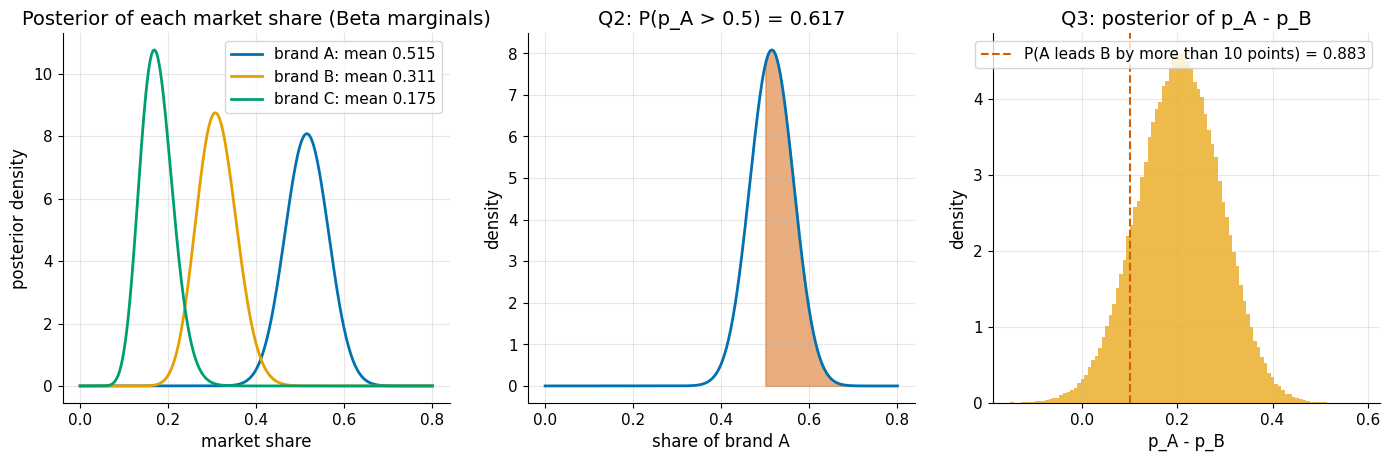

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
grid_p = np.linspace(0.0, 0.8, 500)
for name, a, color in zip("ABC", posterior_alpha, COLORS):
    axes[0].plot(grid_p, stats.beta(a, alpha0 - a).pdf(grid_p), color=color, linewidth=2, label=f"brand {name}: mean {a / alpha0:.3f}")
axes[0].set_title("Posterior of each market share (Beta marginals)")
axes[0].set_xlabel("market share")
axes[0].set_ylabel("posterior density")
axes[0].legend()

axes[1].plot(grid_p, stats.beta(53, 50).pdf(grid_p), color=MAIN, linewidth=2)
above = grid_p > 0.5
axes[1].fill_between(grid_p[above], stats.beta(53, 50).pdf(grid_p[above]), color=HIGHLIGHT, alpha=0.5)
axes[1].set_title(f"Q2: P(p_A > 0.5) = {p_majority_code:.3f}")
axes[1].set_xlabel("share of brand A")
axes[1].set_ylabel("density")

difference = draws_a[:200_000, 0] - draws_a[:200_000, 1]
axes[2].hist(difference, bins=100, density=True, color=SIM, alpha=0.7)
axes[2].axvline(0.10, color=HIGHLIGHT, linestyle="--", label=f"P(A leads B by more than 10 points) = {p_lead_a:.3f}")
axes[2].set_title("Q3: posterior of p_A - p_B")
axes[2].set_xlabel("p_A - p_B")
axes[2].set_ylabel("density")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- The best estimates of the shares are **51 % (A), 31 % (B) and 17 % (C)**, each with an uncertainty of about 4 to 5 points.
- Brand A has a majority with probability only **about 62 %**: from 100 respondents we cannot be sure that A has more than half of the market.
- A is ahead of B by more than 10 points with probability about **88 %**: the *ranking* is fairly clear even though the exact shares are not.
- **Decision:** plan on A leading and B second, but do not announce "majority share" without a larger survey; with about 400 respondents the interval would be half as wide.

### 11.6 Extra example: topic mixtures (the idea behind LDA)
A document is a mix of 4 topics. Under Dirichlet($\alpha,\dots,\alpha$), what is the expected **share of the dominant topic** for $\alpha=0.1$, 1 and 10?

In [15]:
for alpha_value in (0.1, 1.0, 10.0):
    mixtures = rng.dirichlet([alpha_value] * 4, size=200_000)
    dominant = mixtures.max(axis=1)
    print(f"alpha = {alpha_value:>4}: expected share of the top topic = {dominant.mean():.3f}; P(top topic > 70 %) = {np.mean(dominant > 0.7):.3f}")
mixtures = rng.dirichlet([0.1] * 4, size=200_000).max(axis=1)
assert mixtures.mean() > 0.8                                               # sparse mixtures: one topic dominates
assert rng.dirichlet([10.0] * 4, size=200_000).max(axis=1).mean() < 0.4     # smooth mixtures: near 1/4 each

alpha =  0.1: expected share of the top topic = 0.847; P(top topic > 70 %) = 0.779
alpha =  1.0: expected share of the top topic = 0.520; P(top topic > 70 %) = 0.108
alpha = 10.0: expected share of the top topic = 0.335; P(top topic > 70 %) = 0.000


**Interpretation.** With a small alpha (0.1) each document is dominated by a single topic (the top topic holds about 85 % of the words on average); with alpha = 10 the mixture is smooth (the top topic only about a third). In topic models, **alpha is the knob that controls how focused documents are**.

## 12. Where it is used

### Statistics
- **Bayesian inference for categorical data:** posterior of multinomial probabilities, credible regions on the simplex, Dirichlet-Multinomial models for overdispersed counts.

### Data science
- **Share and mix analysis:** market shares, survey results, A/B/C tests with several outcomes; Laplace smoothing in count tables.

### ML and AI
- **Topic models (LDA)**, **Naive Bayes** with Dirichlet smoothing, **Dirichlet processes** and mixture-model priors, mixing weights in Gaussian mixtures (03_03), label smoothing and mixup variants.

## 13. Common pitfalls and misconceptions

- **A Dirichlet draw is a probability vector,** not a count; counts come from a Multinomial given that vector.
- **Components are negatively dependent** (they sum to 1): do not treat them as independent Betas.
- **alpha = 1 is flat, alpha < 1 is not "weaker":** it favours the corners (sparse vectors).
- **The marginal Beta uses alpha_0 - alpha_i as the second parameter,** not the other alpha's separately.
- **Probabilities of differences (p_A - p_B > 0.1) need the joint,** not the two marginals; use simulation.
- **Concentration alpha_0 is the amount of prior data:** a huge alpha_0 swamps the survey.

## 14. Exercises

1. For Dirichlet$(2,3,5)$ find the mean vector, the variance of the first component and its marginal distribution.
2. A die is rolled 60 times with counts $(8,12,9,11,10,10)$. Starting from Dirichlet(1,...,1), what is the posterior mean of the probability of a six?
3. Show that Dirichlet$(1,1,1)$ is uniform on the triangle (all density values equal) and find that value.
4. Using the posterior in the market-share example, what is the probability that brand C has a share below 15 %?
5. (Harder) Find the Dirichlet-Multinomial variance of $X_1$ for $n=20$, $\boldsymbol\alpha=(1,1,2)$, and compare with the Multinomial variance with the same $\mathbf p$.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | alpha_1..alpha_K > 0 (alpha_0 = sum) |
| Support | simplex: p_i >= 0, sum p_i = 1 |
| Density | Gamma(alpha_0) / prod Gamma(alpha_i) x prod p_i^(alpha_i - 1) |
| Mean | alpha_i / alpha_0 |
| Variance | alpha_i (alpha_0 - alpha_i) / (alpha_0^2 (alpha_0 + 1)) |
| Covariance | - alpha_i alpha_j / (alpha_0^2 (alpha_0 + 1)) |
| Marginal | p_i ~ Beta(alpha_i, alpha_0 - alpha_i) |
| Conjugacy | Dir(alpha) + counts x -> Dir(alpha + x) |
| `scipy` | `stats.dirichlet(alpha)`, `rng.dirichlet(alpha)` |

## Solutions

In [16]:
a1 = np.array([2.0, 3.0, 5.0])
print("1: mean", (a1 / a1.sum()).round(3), " var(p1) =", round(2 * 8 / (100 * 11), 5), " marginal Beta(2, 8)")
print("2: posterior mean of a six =", (1 + 10) / (6 + 60))
d3 = stats.dirichlet([1, 1, 1])
print("3: density everywhere =", d3.pdf([0.2, 0.3, 0.5]), d3.pdf([0.6, 0.3, 0.1]), "= Gamma(3) = 2")
print("4: P(p_C < 0.15) =", round(stats.beta(18, 85).cdf(0.15), 4))
n, a5 = 20, np.array([1.0, 1.0, 2.0])
p1 = a5[0] / a5.sum()
print("5: Dirichlet-Multinomial var =", n * p1 * (1 - p1) * (n + a5.sum()) / (1 + a5.sum()), " Multinomial var =", n * p1 * (1 - p1))

1: mean [0.2 0.3 0.5]  var(p1) = 0.01455  marginal Beta(2, 8)
2: posterior mean of a six = 0.16666666666666666
3: density everywhere = 2.0 2.0 = Gamma(3) = 2
4: P(p_C < 0.15) = 0.2643
5: Dirichlet-Multinomial var = 18.0  Multinomial var = 3.75


**1.** Mean $(0.2,0.3,0.5)$; $\mathrm{Var}(p_1)=\frac{2\cdot8}{100\cdot11}=0.01455$; $p_1\sim\text{Beta}(2,8)$.

**2.** Posterior Dirichlet$(9,13,10,12,11,11)$; mean of the six $=\frac{11}{66}=0.1667$.

**3.** With $\alpha_i=1$ the density is $\Gamma(3)/1=2$ everywhere on the triangle (area $\frac12$ in $(p_1,p_2)$ coordinates, so the total is 1).

**4.** The marginal of $p_C$ is Beta$(18,85)$; $P(p_C<0.15)\approx0.26$ (printed).

**5.** $p_1=0.25$: Multinomial variance $20\cdot0.25\cdot0.75=3.75$; Dirichlet-Multinomial: $3.75\times\frac{24}{5}=18$: much larger, because $\alpha_0=4$ is a weak prior (little certainty about $\mathbf p$).